In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import networkx as nx
import torch
from torch_geometric.data import TemporalData
from torch_geometric.loader import TemporalDataLoader
from torch_geometric.nn import TGNMemory, TransformerConv
from torch_geometric.nn.models.tgn import (
    IdentityMessage,
    LastAggregator,
    LastNeighborLoader,
)
from collections import defaultdict
from torch.nn import Linear
from torch_geometric.datasets import JODIEDataset
from sklearn.metrics import average_precision_score, roc_auc_score
import copy
import urllib.request
import os

c:\Users\vince\anaconda3\envs\aml\Lib\site-packages\torch\jit\_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


## Data Loading 

In [2]:
files = ["soc-redditHyperlinks-body.tsv", "soc-redditHyperlinks-title.tsv"]
base_url = "https://snap.stanford.edu/data/"
data_dir = "data"
os.makedirs(data_dir, exist_ok=True)

#SNAP serves the files as plain .tsv (the .gz versions do not exist), so they can be downloaded directly
for f in files:
    path = os.path.join(data_dir, f)
    if not os.path.exists(path):
        url = base_url + f
        print(f"Downloading {f} from {url}...")
        urllib.request.urlretrieve(url, path)
        print(f"Downloaded {f}.")
    else:
        print(f"{f} already downloaded.")

body_df = pd.read_csv(os.path.join(data_dir, "soc-redditHyperlinks-body.tsv"), sep="\t")

title_df = pd.read_csv(os.path.join(data_dir, "soc-redditHyperlinks-title.tsv"), sep="\t")


soc-redditHyperlinks-body.tsv already downloaded.
soc-redditHyperlinks-title.tsv already downloaded.


## Preprocessing and Data Exploration

1- Inspect the data shape, columns and data types. 

In [3]:
body_df.info()



<class 'pandas.DataFrame'>
RangeIndex: 286561 entries, 0 to 286560
Data columns (total 6 columns):
 #   Column            Non-Null Count   Dtype
---  ------            --------------   -----
 0   SOURCE_SUBREDDIT  286561 non-null  str  
 1   TARGET_SUBREDDIT  286561 non-null  str  
 2   POST_ID           286561 non-null  str  
 3   TIMESTAMP         286561 non-null  str  
 4   LINK_SENTIMENT    286561 non-null  int64
 5   PROPERTIES        286561 non-null  str  
dtypes: int64(1), str(5)
memory usage: 13.1 MB


In [4]:
title_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 571927 entries, 0 to 571926
Data columns (total 6 columns):
 #   Column            Non-Null Count   Dtype
---  ------            --------------   -----
 0   SOURCE_SUBREDDIT  571927 non-null  str  
 1   TARGET_SUBREDDIT  571927 non-null  str  
 2   POST_ID           571927 non-null  str  
 3   TIMESTAMP         571927 non-null  str  
 4   LINK_SENTIMENT    571927 non-null  int64
 5   PROPERTIES        571927 non-null  str  
dtypes: int64(1), str(5)
memory usage: 26.2 MB


2- **selection and combining:** for this project we only need the links between subreddits and the timing of the link formation, we don't distinguish between links in the body or in title so we can stack the body and title tables as they have the same columns and data types. 


In [5]:

#we can simply concatenate the two dataframes to get a single dataframe with all the data
#in_title records where the hyperlink appears (0 = post body, 1 = post title), used as an edge feature for TGN
df = pd.concat([body_df.assign(in_title=0), title_df.assign(in_title=1)], ignore_index=True)

#we only need the source, target, post id, timestamp and link position columns, so we can drop the rest of the columns
df = df[["SOURCE_SUBREDDIT", "TARGET_SUBREDDIT", "POST_ID", "TIMESTAMP", "in_title"]]

#rename for convenience
df = df.rename(columns={"SOURCE_SUBREDDIT": "source", "TARGET_SUBREDDIT": "target", "POST_ID": "post_id", "TIMESTAMP": "time"})

#lowercase the subreddit names for consistency
df["source"] = df["source"].str.lower()
df["target"] = df["target"].str.lower()

#convert time to datetime
df["time"] = pd.to_datetime(df["time"])

#sort by time
df = df.sort_values("time")

#duplicate check: the same post linking the same target twice would be a duplicate event
#(no post appears in both the title and body tables, so stacking them creates no duplicates)
print("posts in both tables:", len(set(body_df["POST_ID"]) & set(title_df["POST_ID"])))
print("duplicate (post_id, source, target) rows:", df.duplicated(["post_id", "source", "target"]).sum())
#a post can link several targets, so post_id is not unique per row; these are distinct edges and are kept
print("posts linking more than one target:", (df.groupby("post_id")["target"].nunique() > 1).sum())

df.info()

posts in both tables: 0
duplicate (post_id, source, target) rows: 0
posts linking more than one target: 12547
<class 'pandas.DataFrame'>
Index: 858488 entries, 286584 to 284310
Data columns (total 5 columns):
 #   Column    Non-Null Count   Dtype         
---  ------    --------------   -----         
 0   source    858488 non-null  str           
 1   target    858488 non-null  str           
 2   post_id   858488 non-null  str           
 3   time      858488 non-null  datetime64[us]
 4   in_title  858488 non-null  int64         
dtypes: datetime64[us](1), int64(1), str(3)
memory usage: 39.3 MB


In [6]:
#check for missing values
df.isnull().sum()

source      0
target      0
post_id     0
time        0
in_title    0
dtype: int64

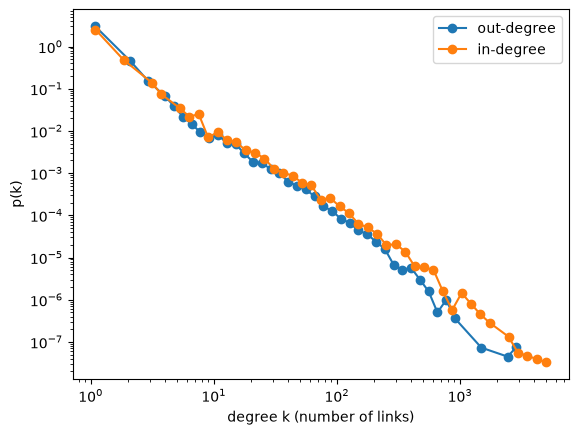

In [7]:

#create a directed graph from the dataframe
G = nx.from_pandas_edgelist(df, source="source", target="target", edge_attr="time", create_using=nx.DiGraph())

#check degree distribution 
out_deg = [d for n, d in G.out_degree()]
in_deg = [d for n, d in G.in_degree()]

def plot_logbinned(values, label, n_bins=50):
    x = np.asarray(values)   
    x = x[x > 0]  # remove zero values to avoid log(0) 
    bins = np.logspace(np.log10(x.min()), np.log10(x.max() + 1), n_bins)
    counts, edges = np.histogram(x, bins=bins)
    density = counts / (np.diff(edges) * len(x))  # divide by bin width and total
    centers = np.sqrt(edges[:-1] * edges[1:])     # geometric bin centers
    mask = counts > 0                             # empty bins can't be shown on log scale
    plt.loglog(centers[mask], density[mask], marker="o", linestyle="-", label=label)

plot_logbinned(out_deg, "out-degree")
plot_logbinned(in_deg, "in-degree")
plt.xlabel("degree k (number of links)")
plt.ylabel("p(k)")
plt.legend()
plt.show()



 


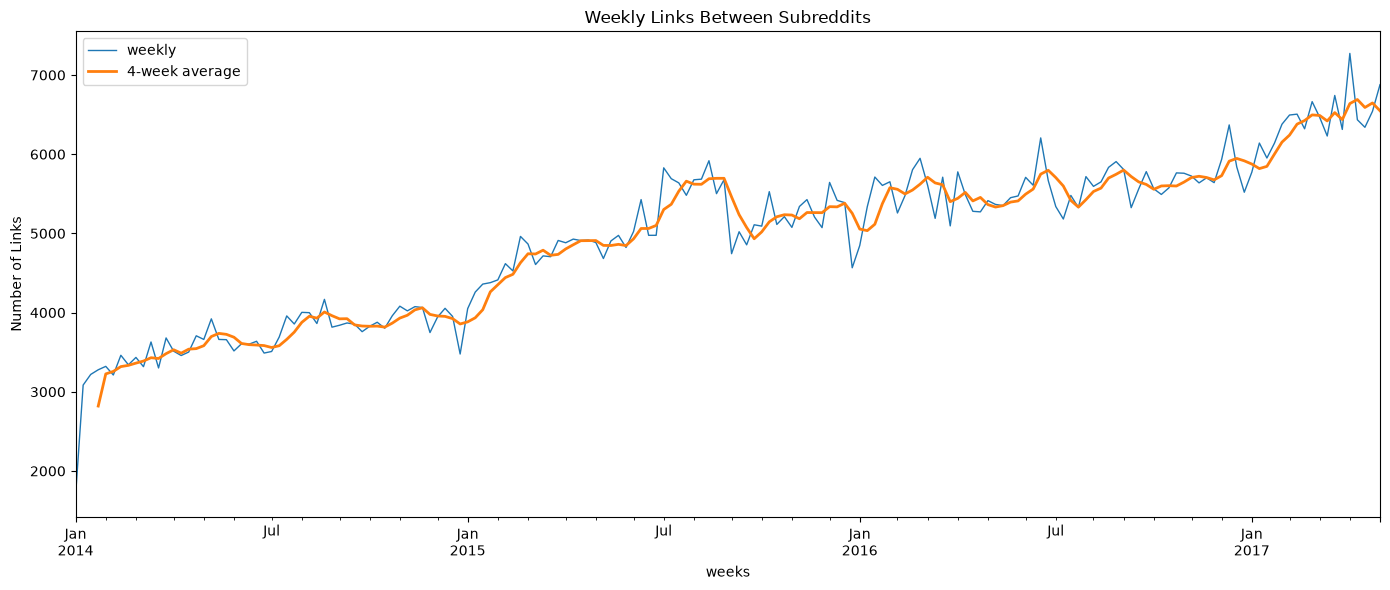

In [8]:

#count number of rows/links per week in the dataframe 
def weekly_links(df):
    
    weekly = (
    df.set_index("time")
      .resample("W")
      .size()        
      .rename("count")
)
    
    return weekly 

weekly = weekly_links(df)

#plot the time evolution of linking beteween subreddits 
fig, ax = plt.subplots(figsize= (14,6))
weekly.plot(ax=ax, linewidth=1, alpha=1, label= "weekly")
weekly.rolling(4).mean().plot(ax=ax, linewidth=2, label="4-week average")

ax.set_xlabel("weeks")
ax.set_ylabel("Number of Links")

ax.set_title("Weekly Links Between Subreddits")

ax.legend()
plt.tight_layout()
plt.show()



In [9]:
#inspect the first week more closely 
start = df["time"].min()
week_1 = df[df['time'] < start + pd.Timedelta(days=7)]

print(week_1)

ts = df["time"].iloc[0]    
ts.day_name()



                 source           target  post_id                time  \
286584        agitation     changemyview  1u5cj7s 2013-12-31 16:20:20   
286561       rddtgaming         rddtrust  1u4pzzs 2013-12-31 16:39:18   
0       leagueoflegends  teamredditteams  1u4nrps 2013-12-31 16:39:58   
286596   examplesofevil             pics  1u5lhas 2013-12-31 16:40:29   
3                   nfl              cfb  1u4sjvs 2013-12-31 17:37:55   
...                 ...              ...      ...                 ...   
764             writing      selfpublish  1uo0w5s 2014-01-07 16:16:12   
773        winnipegjets           hockey  1uo931s 2014-01-07 16:16:48   
288347   examplesofevil         politics  1uo5jts 2014-01-07 16:17:06   
288346   examplesofevil        worldnews  1uo5g2s 2014-01-07 16:17:06   
288148     irishtourism          ireland  1umap6s 2014-01-07 16:19:49   

        in_title  
286584         1  
286561         1  
0              0  
286596         1  
3              0  
...      

'Tuesday'

60.4% of links are repeats of an existing source->target pair


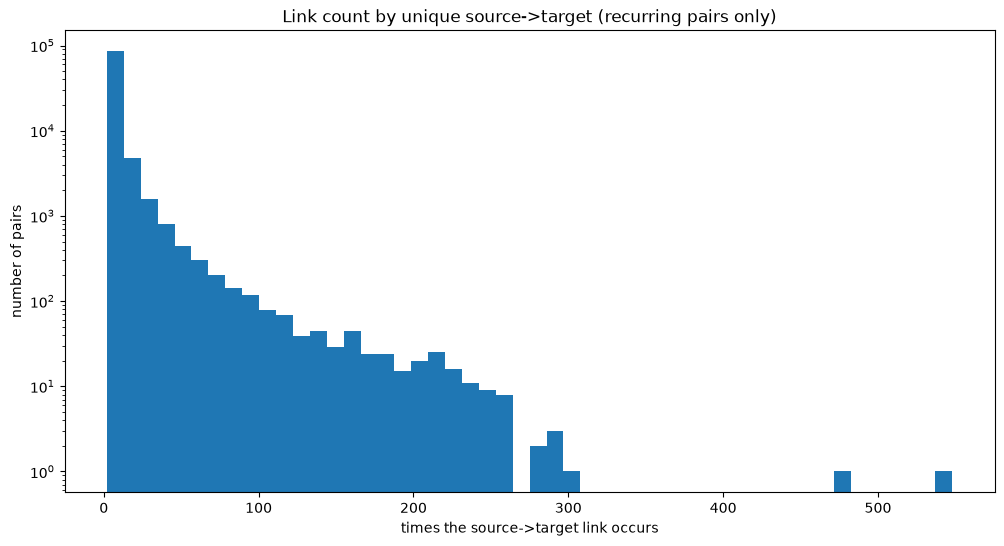

In [10]:
#count recurring links  
# count recurring links
unique_counts = df.groupby(["source", "target"]).size().reset_index(name="count")

recurring = unique_counts[unique_counts["count"] > 1].copy()
recurring["repeats"] = recurring["count"] - 1          # extra occurrences beyond the first

percent_recurring = recurring["repeats"].sum() / len(df)
print(f"{percent_recurring:.1%} of links are repeats of an existing source->target pair")

fig, ax = plt.subplots(figsize=(12, 6))
ax.hist(recurring["count"], bins=50)

ax.set_xlabel("times the source->target link occurs")
ax.set_ylabel("number of pairs")
ax.set_title("Link count by unique source->target (recurring pairs only)")
ax.set_yscale('log')
plt.show()


In [11]:


def inter_event_times(df):
    '''compute inter-event times for each source subreddit (no deduplication)'''
    d = df.sort_values(["source", "time"])
    return d.groupby("source")["time"].diff().dt.total_seconds().dropna()

iet = inter_event_times(df)

# zero gaps (same-second events) cannot be shown on a log axis: report them separately
n_zero = (iet == 0).sum()
print(f"zero gaps: {n_zero} ({n_zero / len(iet):.1%} of all inter-event times)")

iet_pos = iet[iet > 0]


zero gaps: 124066 (15.5% of all inter-event times)


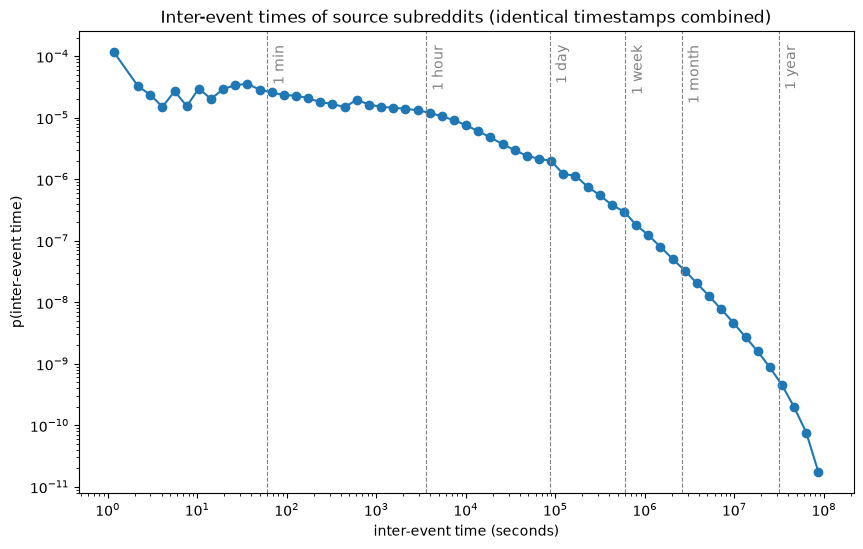

In [12]:
#since 15.5% of events have identical timestamps for the same source subreddit, we can apply deduplication to avoid zero inter-event times
def iet_deduplicated(df):
    '''apply deduplication of events with identical timestamps for the same source subreddit and compute inter-event times'''    
    d = df[["source", "time"]].drop_duplicates()
    iet = inter_event_times(d)
    return iet 

iet = iet_deduplicated(df)


# log-binned histogram of the deduplicated gaps (all positive after combining identical timestamps)
bins = np.logspace(np.log10(iet.min()), np.log10(iet.max()), 60)
counts, edges = np.histogram(iet, bins=bins)
density = counts / (np.diff(edges) * len(iet))
centers = np.sqrt(edges[:-1] * edges[1:])
mask = counts > 0

#plotting 
fig, ax = plt.subplots(figsize=(10, 6))
ax.loglog(centers[mask], density[mask], marker="o", linestyle="-")
for sec, lab in [(60, "1 min"), (3600, "1 hour"), (86400, "1 day"), (7 * 86400, "1 week"),
                 (30 * 86400, "1 month"), (365 * 86400, "1 year")]:
    ax.axvline(sec, color="grey", linewidth=0.8, linestyle="--")
    ax.text(sec * 1.15, 0.97, lab, transform=ax.get_xaxis_transform(), rotation=90, va="top", color="grey")
ax.set_xlabel("inter-event time (seconds)")
ax.set_ylabel("p(inter-event time)")
ax.set_title("Inter-event times of source subreddits (identical timestamps combined)")
plt.show()



In [13]:
#split the data into training, validation and test sets based on time
bounds = df["time"].quantile([0.7, 0.85]).values

print(bounds)

#rounds down to the start of the week (Monday), so each split boundary falls on a week start 
bounds = pd.to_datetime(bounds).to_period("W").to_timestamp()

print(bounds) 

train_df = df[df["time"] < bounds[0]]
valid_df = df[(df["time"] >= bounds[0]) & (df["time"] < bounds[1])]
test_df = df[df["time"] >= bounds[1]]

['2016-07-03T14:55:08.100000' '2016-12-09T15:44:40.000000']
DatetimeIndex(['2016-06-27', '2016-12-05'], dtype='datetime64[us]', freq=None)


In [14]:
def burstiness(iet):
    '''Burstiness B = (sigma - mu) / (sigma + mu) (Goh and Barabasi 2008).
    iet: inter-event times of one unit (array-like). Returns NaN if fewer than 2 gaps.'''
    iet = np.asarray(iet, dtype=float)
    iet = iet[~np.isnan(iet)]
    if len(iet) < 2:
        return np.nan
    mu, sigma = iet.mean(), iet.std(ddof=0)
    if mu == 0:
        return np.nan
    r = sigma / mu
    return (r - 1) / (r + 1)


def burstiness_corrected(iet):
    '''Finite-size corrected burstiness A_n (Kim and Jo 2016), with n = number of events
    = number of inter-event times + 1. Returns NaN if fewer than 2 gaps.'''
    iet = np.asarray(iet, dtype=float)
    iet = iet[~np.isnan(iet)]
    if len(iet) < 2:
        return np.nan
    mu, sigma = iet.mean(), iet.std(ddof=0)
    if mu == 0:
        return np.nan
    r = sigma / mu
    n = len(iet) + 1
    return (np.sqrt(n + 1) * r - np.sqrt(n - 1)) / ((np.sqrt(n + 1) - 2) * r + np.sqrt(n - 1))

         sources  mean_B  median_B  q25_B  q75_B  mean_A  median_A  q25_A  q75_A
n                                                                               
3-4         5163  -0.286    -0.216 -0.452 -0.075  -0.160    -0.127 -0.474  0.179
5-9         4266  -0.082    -0.078 -0.195  0.042   0.025     0.005 -0.175  0.203
10-19       2551   0.014     0.001 -0.089  0.106   0.084     0.054 -0.069  0.202
20-49       1969   0.058     0.035 -0.037  0.126   0.099     0.064 -0.025  0.183
50-99        831   0.089     0.059  0.001  0.147   0.114     0.076  0.008  0.177
100-199      475   0.090     0.057  0.006  0.133   0.106     0.068  0.011  0.152
200-499      257   0.072     0.039  0.001  0.091   0.081     0.043  0.003  0.098
500+          96   0.067     0.033 -0.001  0.072   0.071     0.035 -0.001  0.076


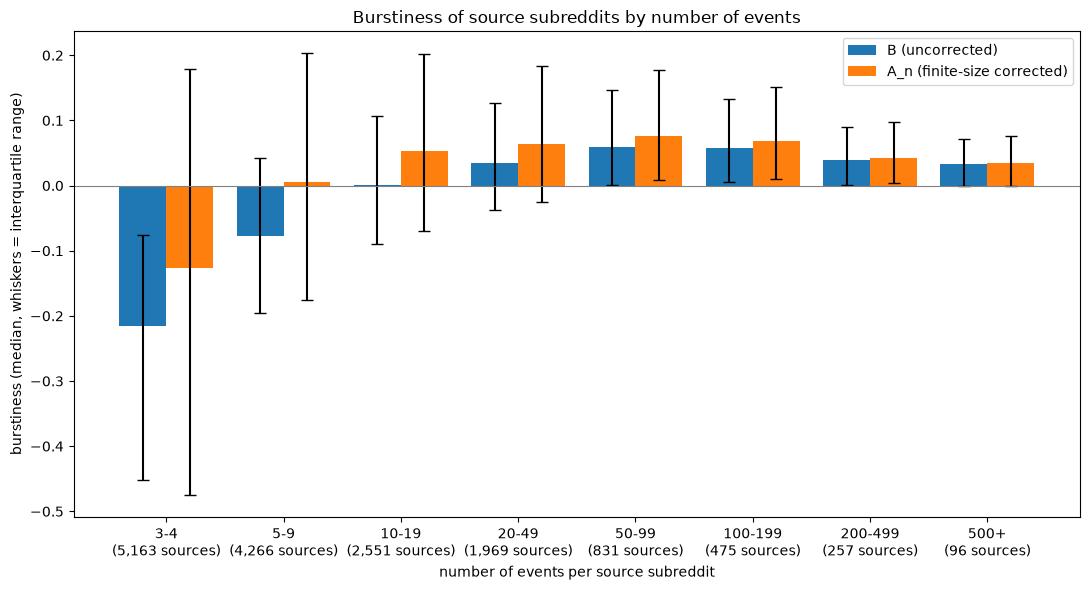

In [15]:
#burstiness by number of events n: B is biased for short sequences, A_n corrects for this
#the cutoff for source activity can be chosen where the median stops changing with n

def source_burstiness(iet, sources, min_events=3):
    '''per source subreddit: number of events n, burstiness B and corrected A_n '''
    by_source = iet.groupby(sources.loc[iet.index])
    table = pd.DataFrame({
        "n": by_source.size() + 1,   # n events give n - 1 inter-event times
        "B": by_source.apply(burstiness),
        "A": by_source.apply(burstiness_corrected),
    })
    return table[table["n"] >= min_events]


def range_labels(edges):
    '''readable labels for integer bins [lo, hi): "3-4", "5-9", ..., "500+"'''
    labels = []
    for lo, hi in zip(edges[:-1], edges[1:]):
        if np.isinf(hi):
            labels.append(f"{lo}+")
        elif hi - lo == 1:
            labels.append(f"{lo}")
        else:
            labels.append(f"{lo}-{int(hi) - 1}")
    return labels


def q25(x):
    return x.quantile(0.25)


def q75(x):
    return x.quantile(0.75)


def burstiness_by_n(table, edges):
    '''mean, median and interquartile range of B and A_n per range of number of events'''
    n_range = pd.cut(table["n"], edges, right=False, labels=range_labels(edges))
    return table.groupby(n_range, observed=True).agg(
        sources=("n", "size"),
        mean_B=("B", "mean"),
        median_B=("B", "median"),
        q25_B=("B", q25),
        q75_B=("B", q75),
        mean_A=("A", "mean"),
        median_A=("A", "median"),
        q25_A=("A", q25),
        q75_A=("A", q75),
    )


def iqr_whiskers(summary, measure):
    '''distance from the median down to q25 and up to q75, in the format plt.bar(yerr=...) expects'''
    median = summary[f"median_{measure}"]
    return [median - summary[f"q25_{measure}"], summary[f"q75_{measure}"] - median]


def plot_burstiness_by_n(summary):
    '''grouped bar plot of median B and median A_n per range of number of events,
    with whiskers showing the interquartile range (25th to 75th percentile)'''
    x = np.arange(len(summary))
    width = 0.4
    fig, ax = plt.subplots(figsize=(11, 6))
    ax.bar(x - width / 2, summary["median_B"], width, yerr=iqr_whiskers(summary, "B"),
           capsize=4, label="B (uncorrected)")
    ax.bar(x + width / 2, summary["median_A"], width, yerr=iqr_whiskers(summary, "A"),
           capsize=4, label="A_n (finite-size corrected)")
    ax.axhline(0, color="grey", linewidth=0.8)
    ax.set_xticks(x)
    ax.set_xticklabels([f"{lab}\n({k:,} sources)" for lab, k in zip(summary.index, summary["sources"])])
    ax.set_xlabel("number of events per source subreddit")
    ax.set_ylabel("burstiness (median, whiskers = interquartile range)")
    ax.set_title("Burstiness of source subreddits by number of events")
    ax.legend()
    plt.tight_layout()
    plt.show()


#computed on the training period only, so no information from the validation or test period is used
n_edges = [3, 5, 10, 20, 50, 100, 200, 500, np.inf]

#deduplicated inter-event times of the training period (iet_deduplicated from the inter-event time cell above)
iet_train = iet_deduplicated(train_df)
b_src = source_burstiness(iet_train, train_df["source"])
by_n = burstiness_by_n(b_src, n_edges)
print(by_n.round(3).to_string())
plot_burstiness_by_n(by_n)

In [16]:
cutoff = 10
keep = set(b_src.index[b_src["n"] >= cutoff])     # source subreddits with >= cutoff events in the training period

def report(df_before, df_after, label):
    nodes_before = len(set(df_before["source"]) | set(df_before["target"]))
    nodes_after = len(set(df_after["source"]) | set(df_after["target"]))
    links_before, links_after = len(df_before), len(df_after)
    print(f"{label}")
    print(f"  nodes: {nodes_before} -> {nodes_after}, removed {nodes_before - nodes_after} "
          f"({(nodes_before - nodes_after) / nodes_before:.1%})")
    print(f"  links: {links_before} -> {links_after}, removed {links_before - links_after} "
          f"({(links_before - links_after) / links_before:.1%})")

src_ok = train_df["source"].isin(keep)
tgt_ok = train_df["target"].isin(keep)

report(train_df, train_df[src_ok], "A) filter on source only (training period)")
report(train_df, train_df[src_ok & tgt_ok], "B) filter on source and target (training period)")

A) filter on source only (training period)
  nodes: 51940 -> 23855, removed 28085 (54.1%)
  links: 595871 -> 504132, removed 91739 (15.4%)
B) filter on source and target (training period)
  nodes: 51940 -> 6157, removed 45783 (88.1%)
  links: 595871 -> 440749, removed 155122 (26.0%)


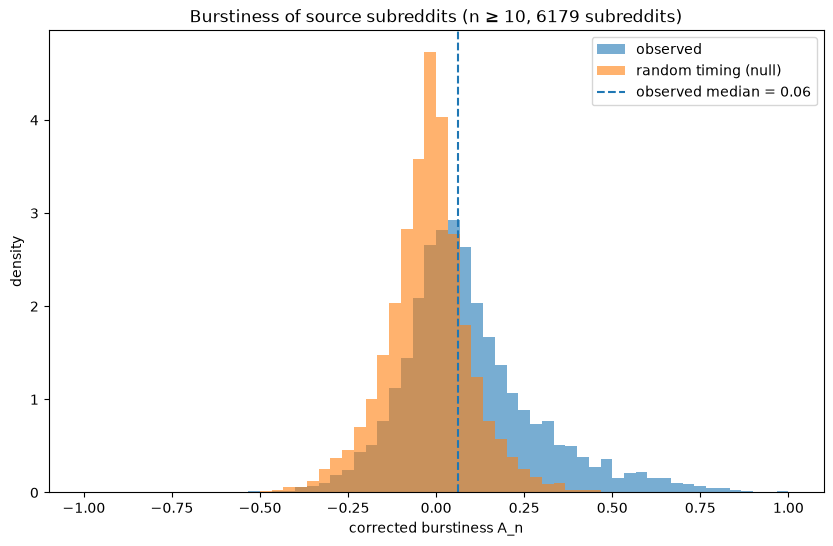

null 95th percentile: 0.17; observed share above it: 26.3% (5% expected under random timing)


In [17]:
rng = np.random.default_rng(42)

real = b_src[b_src["n"] >= cutoff]   # same activity cutoff as the cell above

# null: same number of events per subreddit, but random (Poisson) timing
null_A = [burstiness_corrected(rng.exponential(1.0, size=n - 1)) for n in real["n"]]

bins = np.linspace(-1, 1, 61)
fig, ax = plt.subplots(figsize=(10, 6))
ax.hist(real["A"], bins=bins, alpha=0.6, density=True, label="observed")
ax.hist(null_A, bins=bins, alpha=0.6, density=True, label="random timing (null)")
ax.axvline(real["A"].median(), color="C0", linestyle="--", label=f"observed median = {real['A'].median():.2f}")
ax.set_xlabel("corrected burstiness A_n")
ax.set_ylabel("density")
ax.set_title(f"Burstiness of source subreddits (n ≥ {cutoff}, {len(real)} subreddits)")
ax.legend()
plt.show()

thr = np.nanpercentile(null_A, 95)
share = (real["A"] > thr).mean()
print(f"null 95th percentile: {thr:.2f}; observed share above it: {share:.1%} (5% expected under random timing)")

## Model 

### Data split into train, test, eval and built the data input object that will be used by all models 


In [18]:


# make sure data is sorted by time (keep the original index so train_df, valid_df and test_df still match df rows)
df = df.sort_values("time", kind="stable")

# consecutive integer IDs, one shared ID space for sources and targets
names = pd.Index(pd.unique(pd.concat([df["source"], df["target"]])))
df["src"] = names.get_indexer(df["source"])
df["dst"] = names.get_indexer(df["target"])

# time as integer seconds since the first event
df["t"] = (df["time"] - df["time"].min()).dt.total_seconds().astype("int64")

# the event stream which stores the data in a format suitable for PyTorch Geometric's temporal graph neural networks
data = TemporalData(
    src=torch.tensor(df["src"].to_numpy(), dtype=torch.long),
    dst=torch.tensor(df["dst"].to_numpy(), dtype=torch.long),
    t=torch.tensor(df["t"].to_numpy(), dtype=torch.long),
    msg=torch.tensor(df[["in_title"]].to_numpy(), dtype=torch.float),   # minimal edge feature
)
print(data.num_events, data.num_nodes)

858488 67180


In [19]:
train_mask = (df["time"] < bounds[0]).to_numpy()
val_mask   = ((df["time"] >= bounds[0]) & (df["time"] < bounds[1])).to_numpy()
test_mask  = (df["time"] >= bounds[1]).to_numpy()

train_df, valid_df, test_df = df[train_mask], df[val_mask], df[test_mask]
train_data = data[torch.from_numpy(train_mask)]
val_data   = data[torch.from_numpy(val_mask)]
test_data  = data[torch.from_numpy(test_mask)]

C:\Users\vince\AppData\Local\Temp\ipykernel_36880\3976288758.py:6: UserWarning: The given NumPy array is not writable, and PyTorch does not support non-writable tensors. This means writing to this tensor will result in undefined behavior. You may want to copy the array to protect its data or make it writable before converting it to a tensor. This type of warning will be suppressed for the rest of this program. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\torch\csrc\utils\tensor_numpy.cpp:219.)
  train_data = data[torch.from_numpy(train_mask)]


### Basleine prediction model: Edgebank

In [20]:



# ---------- helpers ----------

def to_numpy(data):
    """src, dst, t of a PyG TemporalData object as NumPy arrays."""
    return data.src.cpu().numpy(), data.dst.cpu().numpy(), data.t.cpu().numpy()


def concat(datas):
    """Concatenate several TemporalData splits (in time order) into one (src, dst, t) tuple."""
    parts = [to_numpy(x) for x in datas]
    return tuple(np.concatenate(a) for a in zip(*parts))


# ---------- negatives (sample once, reuse for every model incl. TGN) ----------

def sample_negatives(history, eval_data, num_nodes, seed=0):
    """For each eval event (s, d) draw
    - a random negative: a random node != d
    - a historical negative: a target s linked to in `history`, != d
      (falls back to the random negative if s has no other past target)."""
    rng = np.random.default_rng(seed)
    h_src, h_dst, _ = history
    s_eval, d_eval, _ = to_numpy(eval_data)

    neg_rand = rng.integers(0, num_nodes, size=len(d_eval))
    clash = neg_rand == d_eval
    while clash.any():
        neg_rand[clash] = rng.integers(0, num_nodes, size=clash.sum())
        clash = neg_rand == d_eval

    past = (pd.DataFrame({"s": h_src, "d": h_dst}).drop_duplicates()
              .groupby("s")["d"].apply(np.array))          # source -> distinct past targets
    neg_hist = neg_rand.copy()
    for i, (s, d) in enumerate(zip(s_eval, d_eval)):
        cands = past.get(s)
        if cands is not None:
            cands = cands[cands != d]
            if len(cands):
                neg_hist[i] = rng.choice(cands)

    return neg_rand, neg_hist


# ---------- shared streaming evaluation ----------

def evaluate_streaming(model, history, eval_data, neg_rand, neg_hist, batch_size=200):
    """Give the model the full history, then go through eval_data batch by batch:
    each batch is scored with the history before it, then added to the history.
    Returns one row per eval event: scores of the positive and of both negatives."""
    model.update(*history)
    s, d, t = to_numpy(eval_data)
    out = {"pos": [], "rand": [], "hist": []}
    for start in range(0, len(s), batch_size):
        b = slice(start, start + batch_size)
        out["pos"].append(model.score(s[b], d[b], t[b]))
        out["rand"].append(model.score(s[b], neg_rand[b], t[b]))
        out["hist"].append(model.score(s[b], neg_hist[b], t[b]))
        model.update(s[b], d[b], t[b])
    return pd.DataFrame({k: np.concatenate(v) for k, v in out.items()})


def metrics(scores):
    """AP and AUC of positives vs. random and vs. historical negatives."""
    y = np.r_[np.ones(len(scores)), np.zeros(len(scores))]
    return pd.DataFrame({
        neg: {"AP": average_precision_score(y, np.r_[scores["pos"], scores[neg]]),
              "AUC": roc_auc_score(y, np.r_[scores["pos"], scores[neg]])}
        for neg in ["rand", "hist"]
    })




class EdgeBank:
    """Scores 1 if the pair (s, d) has linked before, else 0 (Poursafaei et al. 2022)."""

    def __init__(self, num_nodes):
        self.num_nodes = num_nodes
        self.seen = set()

    def _keys(self, s, d):
        return (s.astype(np.int64) * self.num_nodes + d).tolist()   # one integer per pair

    def update(self, s, d, t):
        self.seen.update(self._keys(s, d))

    def score(self, s, d, t):
        return np.fromiter((k in self.seen for k in self._keys(s, d)), dtype=float, count=len(s))

In [39]:
num_nodes = data.num_nodes     

                 # from the full TemporalData object
history = concat([train_data, val_data])    # everything before the test period

neg_rand, neg_hist = sample_negatives(history, test_data, num_nodes)
np.save("neg_rand_test.npy", neg_rand)          # reuse exactly these for TGN
np.save("neg_hist_test.npy", neg_hist)

eb_scores = evaluate_streaming(EdgeBank(num_nodes), history, test_data, neg_rand, neg_hist)
print(metrics(eb_scores))

         rand      hist
AP   0.816960  0.452177
AUC  0.818967  0.387611


In [40]:
class Recency:
    """Scores a pair by how recently it last linked: 1 / (1 + time since last link), 0 if never.
    AP and AUC only depend on the ranking of scores, so the time unit (seconds, minutes) doesn't matter."""

    def __init__(self, num_nodes):
        self.num_nodes = num_nodes
        self.last = {}                                  # pair key -> time of last link

    def _keys(self, s, d):
        return (s.astype(np.int64) * self.num_nodes + d).tolist()

    def update(self, s, d, t):
        # events are in time order, so later links overwrite earlier ones for the same pair
        self.last.update(zip(self._keys(s, d), t.tolist()))

    def score(self, s, d, t):
        out = np.zeros(len(s))
        for i, (k, now) in enumerate(zip(self._keys(s, d), t.tolist())):
            last = self.last.get(k)
            if last is not None:
                out[i] = 1.0 / (1.0 + (now - last))
        return out


# baselines use the shared split (time in seconds) and the same test negatives as EdgeBank.
# validation negatives: same recipe and seed as TGN's (cell below), so in full mode they are identical
base_val_neg_rand, base_val_neg_hist = sample_negatives(concat([train_data]), val_data, num_nodes, seed=1)

# a fresh model for each evaluation, since update() accumulates history
rc_val = evaluate_streaming(Recency(num_nodes), concat([train_data]), val_data, base_val_neg_rand, base_val_neg_hist)
rc_test = evaluate_streaming(Recency(num_nodes), history, test_data, neg_rand, neg_hist)
print("Recency val:\n", metrics(rc_val))
print("Recency test:\n", metrics(rc_test))

Recency val:
          rand      hist
AP   0.817738  0.669389
AUC  0.817780  0.570737
Recency test:
          rand      hist
AP   0.819879  0.661693
AUC  0.819782  0.564753


### TGN: uses the nodes pas histories for prediction. 

In [29]:
torch.manual_seed(0)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
num_nodes = data.num_nodes          # full node count, also used in development mode

DEV_FRACTION = None                  # first 20% of the events for quick testing; None = full data

if DEV_FRACTION is None:
    # same split and same negatives as the baselines
    tgn_train, tgn_val, tgn_test = train_data, val_data, test_data
    tgn_neg_rand, tgn_neg_hist = neg_rand, neg_hist
else:
    dev_data = data[: int(DEV_FRACTION * data.num_events)]
    tgn_train, tgn_val, tgn_test = dev_data.train_val_test_split(val_ratio=0.15, test_ratio=0.15)
    tgn_neg_rand, tgn_neg_hist = sample_negatives(concat([tgn_train, tgn_val]), tgn_test, num_nodes)



def rescale_time(d, unit=60):
    """Copy of a TemporalData split with time in minutes (unit=60) instead of seconds."""
    return TemporalData(src=d.src, dst=d.dst, t=d.t // unit, msg=d.msg)

# TGN only: the shared `data` object stays in seconds for the baselines
tgn_train, tgn_val, tgn_test = (rescale_time(x) for x in (tgn_train, tgn_val, tgn_test))

assert len(tgn_neg_rand) == tgn_test.num_events, "negatives don't match the test set"
print(device, tgn_train.num_events, tgn_val.num_events, tgn_test.num_events)

cuda 595871 129299 133318


In [30]:
TRAIN_BATCH = 500   # larger = faster epochs
EVAL_BATCH = 200     # keep equal to the baselines
MEMORY_DIM = TIME_DIM = 100
LR = 0.0001
MAX_EPOCHS = 50
PATIENCE = 5
TRAIN_NEG = "mixed"    # "random" or "mixed" (random + historical)     

train_loader = TemporalDataLoader(tgn_train, batch_size=TRAIN_BATCH, neg_sampling_ratio=1.0)
val_loader = TemporalDataLoader(tgn_val, batch_size=EVAL_BATCH, neg_sampling_ratio=1.0)
test_loader = TemporalDataLoader(tgn_test, batch_size=EVAL_BATCH, neg_sampling_ratio=1.0)

In [31]:
class LinkPredictor(torch.nn.Module):
    def __init__(self, in_channels):
        super().__init__()
        self.lin_src = Linear(in_channels, in_channels)
        self.lin_dst = Linear(in_channels, in_channels)
        self.lin_final = Linear(in_channels, 1)

    def forward(self, z_src, z_dst):
        h = (self.lin_src(z_src) + self.lin_dst(z_dst)).relu()
        return self.lin_final(h)


memory = TGNMemory(
    data.num_nodes, data.msg.size(-1), MEMORY_DIM, TIME_DIM,
    message_module=IdentityMessage(data.msg.size(-1), MEMORY_DIM, TIME_DIM),
    aggregator_module=LastAggregator(),
).to(device)

link_pred = LinkPredictor(in_channels=MEMORY_DIM).to(device)   # takes the memory directly

optimizer = torch.optim.Adam(list(memory.parameters()) + list(link_pred.parameters()), lr=LR)
criterion = torch.nn.BCEWithLogitsLoss()
assoc = torch.empty(data.num_nodes, dtype=torch.long, device=device)

In [32]:

# validation: stored random + historical negatives (history = training period), like the test set
val_neg_rand, val_neg_hist = sample_negatives(concat([tgn_train]), tgn_val, num_nodes, seed=1)


def sample_hist_streaming(data, num_nodes, batch_size, seed=0):
    """One historical negative per event of `data`: a past target of the same source,
    taken only from earlier batches. Falls back to a random node if there is none."""
    rng = np.random.default_rng(seed)
    src, dst, _ = to_numpy(data)

    neg = rng.integers(0, num_nodes, size=len(src))        # random fallback
    clash = neg == dst
    while clash.any():
        neg[clash] = rng.integers(0, num_nodes, size=clash.sum())
        clash = neg == dst

    past_list, past_set = defaultdict(list), defaultdict(set)
    for start in range(0, len(src), batch_size):
        batch = range(start, min(start + batch_size, len(src)))
        for i in batch:                                     # sample from earlier batches only
            cands = past_list.get(src[i])
            if cands:
                for _ in range(10):
                    pick = cands[rng.integers(len(cands))]
                    if pick != dst[i]:
                        neg[i] = pick
                        break
        for i in batch:                                     # then add this batch to the history
            if dst[i] not in past_set[src[i]]:
                past_set[src[i]].add(dst[i])
                past_list[src[i]].append(dst[i])
    return neg


train_neg_hist = sample_hist_streaming(tgn_train, num_nodes, TRAIN_BATCH, seed=2)

In [33]:
#training loop 
def train(train_neg_hist=None):
    """One epoch. With train_neg_hist, each event also gets a historical negative
    and the two negative losses are averaged."""
    memory.train(); link_pred.train()
    memory.reset_state()
    hist_t = (None if train_neg_hist is None
              else torch.as_tensor(train_neg_hist, dtype=torch.long, device=device))
    total_loss, offset = 0, 0
    for batch in train_loader:
        optimizer.zero_grad()
        batch = batch.to(device)
        k = batch.num_events

        n_id = batch.n_id                                   # src, dst, random negatives
        if hist_t is not None:
            neg_h = hist_t[offset:offset + k]
            n_id = torch.cat([n_id, neg_h]).unique()        # add historical negatives
        offset += k
        assoc[n_id] = torch.arange(n_id.size(0), device=device)

        z, _ = memory(n_id)
        z_src = z[assoc[batch.src]]
        pos = link_pred(z_src, z[assoc[batch.dst]])
        neg_r = link_pred(z_src, z[assoc[batch.neg_dst]])
        loss_neg = criterion(neg_r, torch.zeros_like(neg_r))
        if hist_t is not None:
            neg_hs = link_pred(z_src, z[assoc[neg_h]])
            loss_neg = 0.5 * (loss_neg + criterion(neg_hs, torch.zeros_like(neg_hs)))
        loss = criterion(pos, torch.ones_like(pos)) + loss_neg

        memory.update_state(batch.src, batch.dst, batch.t, batch.msg)
        loss.backward()
        optimizer.step()
        memory.detach()
        total_loss += loss.item() * k
    return total_loss / tgn_train.num_events

@torch.no_grad()
def evaluate_stored(loader, neg_rand, neg_hist):
    """Score each test event's real link and its two stored negatives, batch by batch.
    Returns one row per test event (columns pos, rand, hist), like the baselines."""
    memory.eval(); link_pred.eval()
    neg_rand_t = torch.as_tensor(neg_rand, dtype=torch.long, device=device)
    neg_hist_t = torch.as_tensor(neg_hist, dtype=torch.long, device=device)
    out = {"pos": [], "rand": [], "hist": []}
    offset = 0
    for batch in loader:
        batch = batch.to(device)
        k = batch.num_events
        neg_r = neg_rand_t[offset:offset + k]          # this batch's slice of the stored negatives
        neg_h = neg_hist_t[offset:offset + k]
        offset += k

        n_id = torch.cat([batch.src, batch.dst, neg_r, neg_h]).unique()
        assoc[n_id] = torch.arange(n_id.size(0), device=device)
        z, _ = memory(n_id)
        z_src = z[assoc[batch.src]]
        out["pos"].append(link_pred(z_src, z[assoc[batch.dst]]).sigmoid().squeeze(-1).cpu())
        out["rand"].append(link_pred(z_src, z[assoc[neg_r]]).sigmoid().squeeze(-1).cpu())
        out["hist"].append(link_pred(z_src, z[assoc[neg_h]]).sigmoid().squeeze(-1).cpu())

        memory.update_state(batch.src, batch.dst, batch.t, batch.msg)
    assert offset == len(neg_rand)
    return pd.DataFrame({key: torch.cat(v).numpy() for key, v in out.items()})

@torch.no_grad()
def replay(loader):
    """Feed events into the memory without predicting (to rebuild the memory)."""
    memory.eval()
    for batch in loader:
        batch = batch.to(device)
        memory.update_state(batch.src, batch.dst, batch.t, batch.msg)



In [34]:
RETRAIN = False        # True = train again even if a saved model exists (takes ~1 hour on the full data)

run_name = "full" if DEV_FRACTION is None else f"dev{DEV_FRACTION}"
CHECKPOINT = os.path.join("checkpoints", f"tgn_memory_{TRAIN_NEG}_{run_name}.pt")

# settings a saved model must have been trained with to be reused
config = {"dev_fraction": DEV_FRACTION, "train_neg": TRAIN_NEG, "num_nodes": num_nodes,
          "memory_dim": MEMORY_DIM, "time_dim": TIME_DIM, "lr": LR, "train_batch": TRAIN_BATCH,
          "max_epochs": MAX_EPOCHS, "patience": PATIENCE}


def train_with_early_stopping():
    """Train until the validation score has not improved for PATIENCE epochs.
    Returns the parameters of the best epoch and a short summary of the run."""
    best_score, best_epoch, wait, best_state = -1.0, 0, 0, None
    for epoch in range(1, MAX_EPOCHS + 1):
        loss = train(train_neg_hist if TRAIN_NEG == "mixed" else None)
        val_m = metrics(evaluate_stored(val_loader, val_neg_rand, val_neg_hist))
        ap_rand, ap_hist = val_m.loc["AP", "rand"], val_m.loc["AP", "hist"]
        score = float((ap_rand + ap_hist) / 2)
        print(f"Epoch {epoch:02d}  loss {loss:.4f}  val AP rand {ap_rand:.4f}  "
              f"val AP hist {ap_hist:.4f}  score {score:.4f}")

        if score > best_score:
            best_score, best_epoch, wait = score, epoch, 0
            best_state = {"memory": copy.deepcopy(memory.state_dict()),
                          "link_pred": copy.deepcopy(link_pred.state_dict())}
        else:
            wait += 1
            if wait >= PATIENCE:
                print(f"Early stop. Best epoch: {best_epoch} (score {best_score:.4f})")
                break
    return best_state, {"best_epoch": best_epoch, "best_score": best_score}


def save_checkpoint(path, state, info):
    """Write the best parameters, the settings and the run summary to one file."""
    os.makedirs(os.path.dirname(path), exist_ok=True)
    torch.save({"config": config, "info": info, **state}, path)


def load_checkpoint(path):
    """Read a saved model; refuse it if it was trained with different settings."""
    ckpt = torch.load(path, map_location=device)
    if ckpt["config"] != config:
        raise ValueError(f"{path} was trained with other settings:\n{ckpt['config']}\n"
                         f"current settings:\n{config}\nSet RETRAIN = True to train again.")
    return {"memory": ckpt["memory"], "link_pred": ckpt["link_pred"]}, ckpt["info"]


if os.path.exists(CHECKPOINT) and not RETRAIN:
    best_state, info = load_checkpoint(CHECKPOINT)
    print(f"Loaded {CHECKPOINT}: best epoch {info['best_epoch']}, val score {info['best_score']:.4f}")
else:
    best_state, info = train_with_early_stopping()
    save_checkpoint(CHECKPOINT, best_state, info)
    print(f"Saved {CHECKPOINT}")


Epoch 01  loss 1.1086  val AP rand 0.9472  val AP hist 0.6392  score 0.7932
Epoch 02  loss 1.0562  val AP rand 0.9466  val AP hist 0.6575  score 0.8020
Epoch 03  loss 1.0439  val AP rand 0.9507  val AP hist 0.6587  score 0.8047
Epoch 04  loss 1.0418  val AP rand 0.9466  val AP hist 0.6595  score 0.8030
Epoch 05  loss 1.0348  val AP rand 0.9526  val AP hist 0.6824  score 0.8175
Epoch 06  loss 1.0311  val AP rand 0.9478  val AP hist 0.6724  score 0.8101
Epoch 07  loss 1.0194  val AP rand 0.9570  val AP hist 0.6884  score 0.8227
Epoch 08  loss 1.0225  val AP rand 0.9592  val AP hist 0.6993  score 0.8293
Epoch 09  loss 1.0110  val AP rand 0.9570  val AP hist 0.6951  score 0.8260
Epoch 10  loss 1.0195  val AP rand 0.9508  val AP hist 0.6989  score 0.8248
Epoch 11  loss 1.0090  val AP rand 0.9582  val AP hist 0.7113  score 0.8347
Epoch 12  loss 1.0073  val AP rand 0.9605  val AP hist 0.7120  score 0.8363
Epoch 13  loss 0.9997  val AP rand 0.9608  val AP hist 0.7114  score 0.8361
Epoch 14  lo

In [35]:
memory.load_state_dict(best_state["memory"])
link_pred.load_state_dict(best_state["link_pred"])

memory.reset_state()
replay(train_loader)
replay(val_loader)

tgn_scores = evaluate_stored(test_loader, tgn_neg_rand, tgn_neg_hist)
print(metrics(tgn_scores))

# link each score back to its row in the sorted event table (df)
tgn_scores["event_idx"] = np.arange(len(tgn_scores)) + tgn_train.num_events + tgn_val.num_events
if DEV_FRACTION is None:
    tgn_scores.to_csv("scores_tgn_memory.csv", index=False)

         rand      hist
AP   0.909469  0.633159
AUC  0.933466  0.646311


In [ ]:
def breakdown(model_scores, labels, min_n=200):
    """AP and AUC per group and model. Groups smaller than min_n events are skipped."""
    labels = pd.Series(labels)
    rows = []
    for g in sorted(labels.unique()):
        mask = (labels == g).values
        if mask.sum() < min_n:
            continue
        for name, sc in model_scores.items():
            m = metrics(sc[mask])
            rows.append({"group": g, "model": name, "n": int(mask.sum()),
                         "AP rand": m.loc["AP", "rand"], "AP hist": m.loc["AP", "hist"],
                         "AUC rand": m.loc["AUC", "rand"], "AUC hist": m.loc["AUC", "hist"]})
    return pd.DataFrame(rows)


model_scores = {"EdgeBank": eb_test, "Recency": rc_test, "TGN memory": tgn_scores}

for col in ["pair", "burstiness", "onset"]:
    res = breakdown(model_scores, groups[col])
    print(f"\n=== {col} ===")
    print(res.pivot(index="group", columns="model", values="AP hist").round(3))
    print(res.pivot(index="group", columns="model", values="AUC hist").round(3))

In [ ]:
MIN_EVENTS = 20     # minimum training events per source for burstiness / onset threshold
ONSET_Q = 0.9       # a gap above the source's 90th-percentile training gap counts as an onset

s_te, d_te, t_te = to_numpy(tgn_test)
h_src, h_dst, h_t = concat([tgn_train, tgn_val])

# --- 1) repeat vs. new pair: seen in the history or in an earlier test batch ---
seen = set((h_src.astype(np.int64) * num_nodes + h_dst).tolist())
keys = (s_te.astype(np.int64) * num_nodes + d_te).tolist()
repeat = np.zeros(len(keys), dtype=bool)
for start in range(0, len(keys), EVAL_BATCH):           # same batch rule as the models
    b = keys[start:start + EVAL_BATCH]
    repeat[start:start + len(b)] = [k in seen for k in b]
    seen.update(b)

# --- 2) burstiness per source, from training events only ---
tr_src, _, tr_t = to_numpy(tgn_train)
u_tr = pd.DataFrame({"src": tr_src, "t": tr_t}).drop_duplicates().sort_values(["src", "t"])
u_tr["gap"] = u_tr.groupby("src")["t"].diff()            # gaps between distinct event times
stats = u_tr.groupby("src").agg(n=("t", "size"))
stats["A"] = u_tr.groupby("src")["gap"].apply(lambda g: burstiness_corrected(g.dropna().values))
stats["q_gap"] = u_tr.groupby("src")["gap"].quantile(ONSET_Q)
stats = stats[stats["n"] >= MIN_EVENTS]

stats["burst_q"] = pd.qcut(stats["A"], 4, labels=["Q1 least bursty", "Q2", "Q3", "Q4 most bursty"])
burst_group = pd.Series(s_te).map(stats["burst_q"]).astype(object).fillna("too few events").values

# --- 3) onset vs. within burst: gap since the source's previous distinct event time ---
ev = pd.DataFrame({"src": np.r_[h_src, s_te], "t": np.r_[h_t, t_te],
                   "test_pos": np.r_[np.full(len(h_src), -1), np.arange(len(s_te))]})
u = ev[["src", "t"]].drop_duplicates().sort_values(["src", "t"])
u["gap"] = u.groupby("src")["t"].diff()
te = ev[ev["test_pos"] >= 0].merge(u, on=["src", "t"], how="left").sort_values("test_pos")
gap = te["gap"].values
thr = pd.Series(s_te).map(stats["q_gap"]).values
onset = np.where(np.isnan(thr), "too few events",
                 np.where(np.isnan(gap) | (gap > thr), "onset", "within burst"))

groups = pd.DataFrame({"pair": np.where(repeat, "repeat pair", "new pair"),
                       "burstiness": burst_group,
                       "onset": onset})
for col in groups:
    print(groups[col].value_counts(), "\n")